# Day 16: Basic RAG on Company Documentation

**RAG (Retrieval-Augmented Generation)** lets an LLM answer questions using our own documents instead of only what it learned during training.

Pipeline I'm building:

```
Company documents → split into chunks → embeddings → vector search (retrieval) → LLM writes the answer
```

Then I experiment with different **chunk sizes** to see which one gives the best retrieval and the best answers.

**Documents:** 5 policy documents of a sample company, *NovaTech Solutions* (fictional): leave policy, remote work policy, IT security policy, expense policy and onboarding guide.

**Models (both free, open source, run locally on CPU, no API key needed):**
- Embeddings: `sentence-transformers/all-MiniLM-L6-v2`
- LLM: `Qwen/Qwen2.5-0.5B-Instruct`

In [1]:
%pip install numpy pandas matplotlib seaborn sentence-transformers transformers torch

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/760.7 kB ? eta -:--:--
   ---------------------------------------- 760.7/760.7 kB 6.6 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
import re
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from transformers import pipeline

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

C:\Users\akshay\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Documents

Loading all the `.txt` files from the `docs` folder.

In [2]:
DOCS_DIR = "docs"

documents = {}
for file in sorted(os.listdir(DOCS_DIR)):
    if file.endswith(".txt"):
        with open(os.path.join(DOCS_DIR, file), encoding="utf-8") as f:
            documents[file] = f.read()

for name, text in documents.items():
    print(f"{name:<25} {len(text):>6} characters  {len(text.split()):>5} words")

expense_policy.txt          3293 characters    537 words
it_security_policy.txt      3994 characters    630 words
leave_policy.txt            3703 characters    649 words
onboarding_guide.txt        3731 characters    610 words
remote_work_policy.txt      3199 characters    535 words


In [3]:
print(documents["leave_policy.txt"][:700])

NovaTech Solutions - Leave Policy
(Sample company documentation created for this project. NovaTech Solutions is a fictional company.)

1. Purpose
This policy explains the types of leave available to NovaTech employees, how much leave each employee gets, and how to apply for it. It applies to all full-time employees. Interns and contract staff should refer to their offer letter, as their leave terms may be different.

2. Leave Year
The leave year runs from 1 January to 31 December. Leave balances are calculated for this period. Employees who join in the middle of the year receive leave on a pro-rata basis, which means the number of days is reduced according to the months left in the year.

3.


## 2. Chunking

An LLM can only take a limited amount of text, and a whole document is too big and too general to search well. So each document is split into smaller **chunks**.

My chunking function:
- splits on words so a word is never cut in half
- keeps adding words until the chunk reaches `chunk_size` characters
- keeps some **overlap** (about 15%) between chunks, so a sentence at the border of two chunks is not lost
- stores which document each chunk came from

In [4]:
def chunk_text(text, chunk_size, overlap_ratio=0.15):
    words = text.split()
    chunks = []
    start = 0
    while start < len(words):
        end = start
        length = 0
        while end < len(words) and length + len(words[end]) + 1 <= chunk_size:
            length += len(words[end]) + 1
            end += 1
        end = max(end, start + 1)  # at least one word per chunk
        chunks.append(" ".join(words[start:end]))
        if end >= len(words):
            break
        # step back a few words for overlap
        overlap_words = max(1, int((end - start) * overlap_ratio))
        start = end - overlap_words
    return chunks


def make_chunks(chunk_size):
    rows = []
    for name, text in documents.items():
        for i, chunk in enumerate(chunk_text(text, chunk_size)):
            rows.append({"doc": name, "chunk_id": i, "text": chunk})
    return pd.DataFrame(rows)

In [5]:
chunks = make_chunks(500)
print("Number of chunks:", len(chunks))
chunks.head()

Number of chunks: 44


,doc,chunk_id,text
0,expense_policy.txt,0,NovaTech Solutions - Travel and Expense Reimbursement Policy (Sample company documentation created for this project....
1,expense_policy.txt,1,2. General Rules Only expenses that are directly related to company business will be reimbursed. Every claim must ha...
2,expense_policy.txt,2,the Finance Head. 3. Approval Process Claims are first approved by the employee's reporting manager. Claims above Rs...
3,expense_policy.txt,3,at travel@novatech.example. Bookings made personally will only be reimbursed if the travel desk could not make the b...
4,expense_policy.txt,4,"cost per night depends on the city: - Metro cities (Mumbai, Delhi, Bengaluru, Chennai, Hyderabad, Kolkata): Rs. 7,00..."


In [6]:
print(chunks.loc[3, "text"])
print("---")
print(chunks.loc[4, "text"])

at travel@novatech.example. Bookings made personally will only be reimbursed if the travel desk could not make the booking. Domestic flights are booked in economy class for all employees. Employees at the level of Director and above may travel in business class for flights longer than 4 hours. International travel must be approved by the department head at least 21 days before the trip. 5. Hotel Limits The maximum hotel cost per night depends on the city: - Metro cities (Mumbai, Delhi,
---
cost per night depends on the city: - Metro cities (Mumbai, Delhi, Bengaluru, Chennai, Hyderabad, Kolkata): Rs. 7,000 per night - Other cities: Rs. 4,500 per night If an employee stays with friends or family instead of a hotel, they can claim Rs. 1,000 per night as a stay allowance. 6. Daily Allowance During business travel, employees receive a daily allowance (per diem) for food and small expenses. The daily allowance is Rs. 1,200 per day in metro cities and Rs. 800 per day in other cities. No


You can see the end of one chunk is repeated at the start of the next one; that's the overlap.

## 3. Embeddings

An embedding model turns text into a list of numbers (a vector) so that texts with similar **meaning** get similar vectors. `all-MiniLM-L6-v2` gives a 384-number vector for each text.

In [7]:
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

chunk_vectors = embedder.encode(chunks["text"].tolist(), normalize_embeddings=True)
chunk_vectors.shape


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2493.84it/s]

(44, 384)

Quick check that embeddings understand meaning and not just exact words:

In [8]:
test = embedder.encode([
    "How many days off do I get?",
    "Every employee receives 24 days of earned leave per year.",
    "Passwords must be at least 12 characters long.",
], normalize_embeddings=True)

print("question vs leave sentence:   ", round(float(test[0] @ test[1]), 3))
print("question vs password sentence:", round(float(test[0] @ test[2]), 3))

question vs leave sentence:    0.521
question vs password sentence: 0.056


The question doesn't contain the word "leave", but it's still much closer to the leave sentence. That's why embeddings work better than plain keyword search.

## 4. Retrieval

For a question, I embed it the same way and find the chunks with the highest **cosine similarity**. Since the vectors are normalized, cosine similarity is just the dot product.

In [9]:
class VectorStore:
    def __init__(self, chunk_size):
        self.chunk_size = chunk_size
        self.chunks = make_chunks(chunk_size)
        self.vectors = embedder.encode(self.chunks["text"].tolist(), normalize_embeddings=True)

    def search(self, question, top_k=3):
        q = embedder.encode([question], normalize_embeddings=True)[0]
        scores = self.vectors @ q
        best = np.argsort(scores)[::-1][:top_k]
        results = self.chunks.iloc[best].copy()
        results["score"] = scores[best].round(3)
        return results


store = VectorStore(500)
store.search("How many sick leaves do I get?")

,doc,chunk_id,text,score
21,leave_policy.txt,3,unused earned leave at the end of the year instead of carrying it forward. Encashment is paid at the employee's basi...,0.394
19,leave_policy.txt,1,The leave year runs from 1 January to 31 December. Leave balances are calculated for this period. Employees who join...,0.257
20,leave_policy.txt,2,"of each month. Employees can use earned leave for vacations, personal work, or any other reason. Earned leave must b...",0.208


The top result is from the leave policy and it's the sick leave section. Retrieval works.

## 5. LLM: generating the answer

The retrieved chunks are put into the prompt as **context**, and the LLM is told to answer **only** from that context. This is what stops it from making things up.

In [10]:
llm = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct")

SYSTEM_PROMPT = (
    "You are an HR and IT help assistant for NovaTech Solutions. "
    "Answer the question using ONLY the context below. "
    "Give the exact numbers from the context. "
    "If the answer is not in the context, say \"I don't know based on the company documents.\" "
    "Keep the answer to 1-3 sentences."
)


def generate_answer(question, context_chunks):
    context = "\n\n".join(f"[{row.doc}]\n{row.text}" for row in context_chunks.itertuples())
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"},
    ]
    output = llm(messages, max_new_tokens=120, do_sample=False)
    return output[0]["generated_text"][-1]["content"].strip()


def ask(question, store, top_k=3, show_sources=True):
    results = store.search(question, top_k)
    answer = generate_answer(question, results)
    if show_sources:
        print("Q:", question)
        print("A:", answer)
        print("Sources:", ", ".join(f"{r.doc} (chunk {r.chunk_id}, score {r.score})" for r in results.itertuples()))
        print()
    return answer, results


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


Loading weights:   3%|▎         | 8/290 [00:00<00:05, 53.10it/s]


Loading weights:   5%|▍         | 14/290 [00:00<00:09, 29.64it/s]


Loading weights:   6%|▌         | 18/290 [00:00<00:08, 30.58it/s]


Loading weights:   8%|▊         | 22/290 [00:00<00:10, 26.48it/s]


Loading weights:   9%|▊         | 25/290 [00:00<00:12, 21.72it/s]


Loading weights:  10%|▉         | 28/290 [00:01<00:12, 20.83it/s]


Loading weights: 100%|██████████| 290/290 [00:01<00:00, 253.57it/s]

## 6. Project practical: ask questions about the company docs

In [11]:
ask("How many sick leaves do I get in a year?", store);
ask("What should I do if my laptop gets stolen?", store);
ask("Can I work from Goa for two weeks?", store);
ask("What is the referral bonus for a senior role?", store);

Q: How many sick leaves do I get in a year?
A: Based on the information provided in the two text files, you would receive 10 sick leave days per year.
Sources: leave_policy.txt (chunk 3, score 0.4429999887943268), leave_policy.txt (chunk 1, score 0.3700000047683716), leave_policy.txt (chunk 2, score 0.2770000100135803)



Q: What should I do if my laptop gets stolen?
A: If your laptop is stolen, you should report it to the IT helpdesk within 1 hour of noticing. The IT team will remotely lock and wipe the device. You must also file a police report (FIR) within 24 hours and share a copy with the IT team.
Sources: it_security_policy.txt (chunk 4, score 0.5130000114440918), it_security_policy.txt (chunk 3, score 0.40299999713897705), it_security_policy.txt (chunk 2, score 0.30300000309944153)



Q: Can I work from Goa for two weeks?
A: Based on the information provided in the [remote_work_policy.txt] file, fully remote work is allowed only in special cases like a medical condition or relocation for family reasons. Therefore, it is not possible to work from Goa (Goa) for two weeks under this policy.
Sources: remote_work_policy.txt (chunk 3, score 0.5460000038146973), onboarding_guide.txt (chunk 1, score 0.46000000834465027), remote_work_policy.txt (chunk 1, score 0.39800000190734863)



Q: What is the referral bonus for a senior role?
A: The referral bonus for a senior role is Rs. 50,000.
Sources: onboarding_guide.txt (chunk 6, score 0.6499999761581421), onboarding_guide.txt (chunk 7, score 0.328000009059906), onboarding_guide.txt (chunk 5, score 0.24699999392032623)



And a question that is **not** in the documents, to check that the model doesn't make up an answer:

In [12]:
ask("What is the company's policy on pets in the office?", store);

Q: What is the company's policy on pets in the office?
A: The company's policy on pets in the office is that laptops must be locked when not in use, and confidential calls should not be taken in public places.
Sources: remote_work_policy.txt (chunk 6, score 0.3659999966621399), it_security_policy.txt (chunk 0, score 0.3440000116825104), it_security_policy.txt (chunk 7, score 0.3409999907016754)



## 7. RAG retrieval performance analysis: chunk sizes

Now the main experiment. I'll test 4 chunk sizes:

| Chunk size | Roughly |
|---|---|
| 150 characters | 1 sentence |
| 300 characters | 2–3 sentences |
| 600 characters | 1 section |
| 1200 characters | 2–3 sections |

`top_k = 3` for all of them, so only the chunk size changes.

### Test questions

I wrote 12 questions where I know the correct answer from the documents. For each one I listed the **key facts** that a correct answer must contain (with different ways of writing them, like "60" or "sixty"). Some questions need only one fact; some need two facts that are in different sentences, which is harder for small chunks.

In [13]:
test_questions = [
    {"question": "How many days of sick leave do employees get per year?",
     "facts": [["10 days", "ten days", "10 sick"]], "doc": "leave_policy.txt"},
    {"question": "How many earned leave days can be carried forward to next year, and how many can be encashed?",
     "facts": [["10 days", "ten days", "maximum of 10", "up to 10"], ["5 days", "five days", "up to 5"]], "doc": "leave_policy.txt"},
    {"question": "How long is paternity leave and within what time must it be taken?",
     "facts": [["15 days", "fifteen days"], ["3 months", "three months"]], "doc": "leave_policy.txt"},
    {"question": "How many days a week do hybrid employees need to be in the office, and which are the anchor days?",
     "facts": [["3 days", "three days", "3 office"], ["tuesday"], ["thursday"]], "doc": "remote_work_policy.txt"},
    {"question": "What is the monthly internet allowance for remote employees?",
     "facts": [["1500", "1,500"]], "doc": "remote_work_policy.txt"},
    {"question": "What are the core working hours?",
     "facts": [["11:00", "11 am", "11am"], ["4:00", "4 pm", "4pm"]], "doc": "remote_work_policy.txt"},
    {"question": "What is the minimum password length and how often must passwords be changed?",
     "facts": [["12 characters", "12"], ["90 days", "90"]], "doc": "it_security_policy.txt"},
    {"question": "Within how much time must a lost or stolen laptop be reported to the IT helpdesk?",
     "facts": [["1 hour", "one hour"]], "doc": "it_security_policy.txt"},
    {"question": "What is the maximum hotel cost per night in metro cities and in other cities?",
     "facts": [["7000", "7,000"], ["4500", "4,500"]], "doc": "expense_policy.txt"},
    {"question": "Within how many days must expense claims be submitted?",
     "facts": [["30 days", "thirty days"]], "doc": "expense_policy.txt"},
    {"question": "What is the notice period after confirmation?",
     "facts": [["60 days", "sixty days"]], "doc": "onboarding_guide.txt"},
    {"question": "How much is the yearly learning budget per employee?",
     "facts": [["20000", "20,000"]], "doc": "onboarding_guide.txt"},
]
print(len(test_questions), "test questions")

12 test questions


### How I score it

- **Retrieval hit@3**: did any of the 3 retrieved chunks come from the correct document?
- **Context recall**: what fraction of the key facts are actually inside the retrieved text? (If the facts aren't retrieved, the LLM can't answer correctly.)
- **Answer score**: what fraction of the key facts are in the generated answer.
- **Fully correct**: the answer contains all the key facts.
- **Context length**: how many characters are sent to the LLM (more text = slower and more distraction).
- **Time**: seconds to answer.

For matching I lowercase the text and remove commas between digits, so "Rs. 7,000" and "7000" both match.

In [14]:
def normalize(text):
    text = text.lower()
    text = re.sub(r"(?<=\d),(?=\d)", "", text)  # 7,000 -> 7000
    return text


def fact_score(text, facts):
    text = normalize(text)
    found = [any(normalize(option) in text for option in fact) for fact in facts]
    return sum(found) / len(facts)

In [15]:
CHUNK_SIZES = [150, 300, 600, 1200]
TOP_K = 3

results = []
chunk_counts = {}

for size in CHUNK_SIZES:
    size_store = VectorStore(size)
    chunk_counts[size] = len(size_store.chunks)
    print(f"Chunk size {size}: {len(size_store.chunks)} chunks")

    for q in test_questions:
        start = time.time()
        retrieved = size_store.search(q["question"], TOP_K)
        answer = generate_answer(q["question"], retrieved)
        seconds = time.time() - start

        context = " ".join(retrieved["text"])
        answer_score = fact_score(answer, q["facts"])
        results.append({
            "chunk_size": size,
            "question": q["question"],
            "retrieval_hit": q["doc"] in retrieved["doc"].values,
            "context_recall": fact_score(context, q["facts"]),
            "answer_score": answer_score,
            "fully_correct": answer_score == 1.0,
            "context_chars": len(context),
            "seconds": round(seconds, 1),
            "answer": answer,
        })

results = pd.DataFrame(results)
print("Done:", len(results), "answers generated")

Chunk size 150: 142 chunks


Chunk size 300: 72 chunks


Chunk size 600: 37 chunks


Chunk size 1200: 19 chunks


Done: 48 answers generated


## 8. Response evaluation table

Every question, for every chunk size, with the generated answer and its scores.

In [16]:
eval_table = results[["chunk_size", "question", "answer", "retrieval_hit", "context_recall", "answer_score", "fully_correct"]]
eval_table.style.format({"context_recall": "{:.0%}", "answer_score": "{:.0%}"}).hide(axis="index")

chunk_size,question,answer,retrieval_hit,context_recall,answer_score,fully_correct
150,How many days of sick leave do employees get per year?,"Based on the provided leave policies: - Sick Leave: Employees receive 10 days of sick leave per year. - Casual Leave: Employees receive 6 days of casual leave per year for short, unplanned personal needs.",True,100%,100%,True
150,"How many earned leave days can be carried forward to next year, and how many can be encashed?","Based on the information provided in [leave_policy.txt], according to the months left in the year: 1. The policy allows employees to carry forward up to 10 days of earned leave. 2. Any remaining unencashed earned leave after this limit can be carried forward to the following year. So, the total number of earned leave days that can be carried forward to the next year is 10 days, and any excess can be carried over to the following year as well.",True,100%,50%,False
150,How long is paternity leave and within what time must it be taken?,"Paternity leave is 26 weeks long, and it must be taken within 3 months of the child's birth.",True,100%,50%,False
150,"How many days a week do hybrid employees need to be in the office, and which are the anchor days?",Hybrid employees need to work from the office at least 3 days per week. The anchor days are Tuesday and Thursday.,True,100%,100%,True
150,What is the monthly internet allowance for remote employees?,"The monthly internet allowance for remote employees is Rs. 1,500 per month.",True,100%,100%,True
150,What are the core working hours?,"During core hours, which are 11:00 AM to 4:00 PM IST, employees are eligible to work remotely.",True,100%,100%,True
150,What is the minimum password length and how often must passwords be changed?,"The minimum password length requirement is 12 characters long, and passwords must be changed every 90 days.",True,100%,100%,True
150,Within how much time must a lost or stolen laptop be reported to the IT helpdesk?,The IT team will remotely lock and wipe the device. The employee must also file a police report (FIR) within 24 hours and share a copy with the IT team.,True,100%,0%,False
150,What is the maximum hotel cost per night in metro cities and in other cities?,"The maximum hotel cost per night in metro cities is Rs. 7,000 per night, while in other cities it's Rs. 4,500 per night.",True,100%,100%,True
150,Within how many days must expense claims be submitted?,Expense claims must be submitted on the Finance portal within 30 days of the expense date.,True,100%,100%,True


In [17]:
eval_table.to_csv("results/response_evaluation_table.csv", index=False)

Same results as a grid: answer score per question and chunk size.

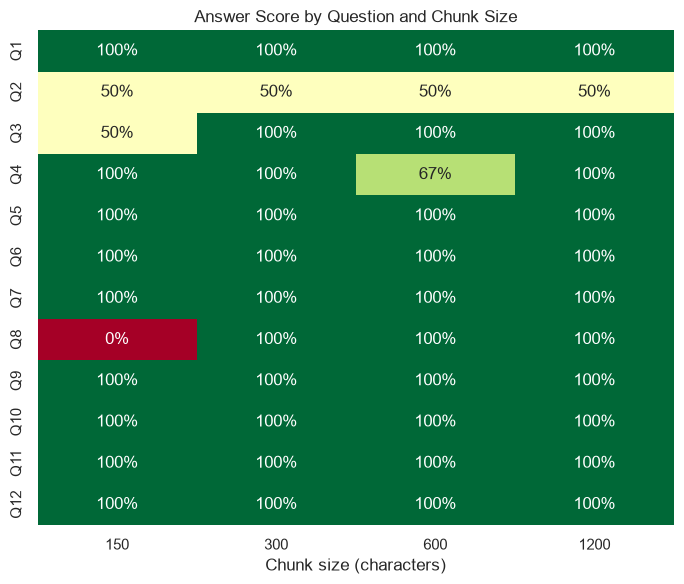

In [18]:
short_q = {q["question"]: f"Q{i+1}" for i, q in enumerate(test_questions)}
grid = results.assign(q=results["question"].map(short_q)).pivot(index="q", columns="chunk_size", values="answer_score")
grid = grid.loc[[f"Q{i+1}" for i in range(len(test_questions))]]

plt.figure(figsize=(7, 6))
sns.heatmap(grid, annot=True, fmt=".0%", cmap="RdYlGn", vmin=0, vmax=1, cbar=False)
plt.title("Answer Score by Question and Chunk Size")
plt.xlabel("Chunk size (characters)")
plt.ylabel("")
plt.tight_layout()
plt.savefig("results/answer_score_heatmap.png", dpi=120)
plt.show()

In [19]:
for i, q in enumerate(test_questions):
    print(f"Q{i+1}: {q['question']}")

Q1: How many days of sick leave do employees get per year?
Q2: How many earned leave days can be carried forward to next year, and how many can be encashed?
Q3: How long is paternity leave and within what time must it be taken?
Q4: How many days a week do hybrid employees need to be in the office, and which are the anchor days?
Q5: What is the monthly internet allowance for remote employees?
Q6: What are the core working hours?
Q7: What is the minimum password length and how often must passwords be changed?
Q8: Within how much time must a lost or stolen laptop be reported to the IT helpdesk?
Q9: What is the maximum hotel cost per night in metro cities and in other cities?
Q10: Within how many days must expense claims be submitted?
Q11: What is the notice period after confirmation?
Q12: How much is the yearly learning budget per employee?


## 9. Comparison

In [20]:
summary = results.groupby("chunk_size").agg(
    retrieval_hit_rate=("retrieval_hit", "mean"),
    context_recall=("context_recall", "mean"),
    answer_score=("answer_score", "mean"),
    fully_correct=("fully_correct", "sum"),
    avg_context_chars=("context_chars", "mean"),
    avg_seconds=("seconds", "mean"),
)
summary.insert(0, "num_chunks", pd.Series(chunk_counts))
summary["fully_correct"] = summary["fully_correct"].astype(int).astype(str) + f" / {len(test_questions)}"
summary["avg_context_chars"] = summary["avg_context_chars"].round().astype(int)
summary["avg_seconds"] = summary["avg_seconds"].round(1)
summary.to_csv("results/chunk_size_comparison.csv")
summary.style.format({"retrieval_hit_rate": "{:.0%}", "context_recall": "{:.0%}", "answer_score": "{:.0%}"})

,num_chunks,retrieval_hit_rate,context_recall,answer_score,fully_correct,avg_context_chars,avg_seconds
chunk_size,,,,,,,
150,142,100%,100%,83%,9 / 12,438,12.500000
300,72,100%,100%,96%,11 / 12,889,16.200000
600,37,100%,100%,93%,10 / 12,1771,24.700000
1200,19,100%,100%,96%,11 / 12,3232,39.000000


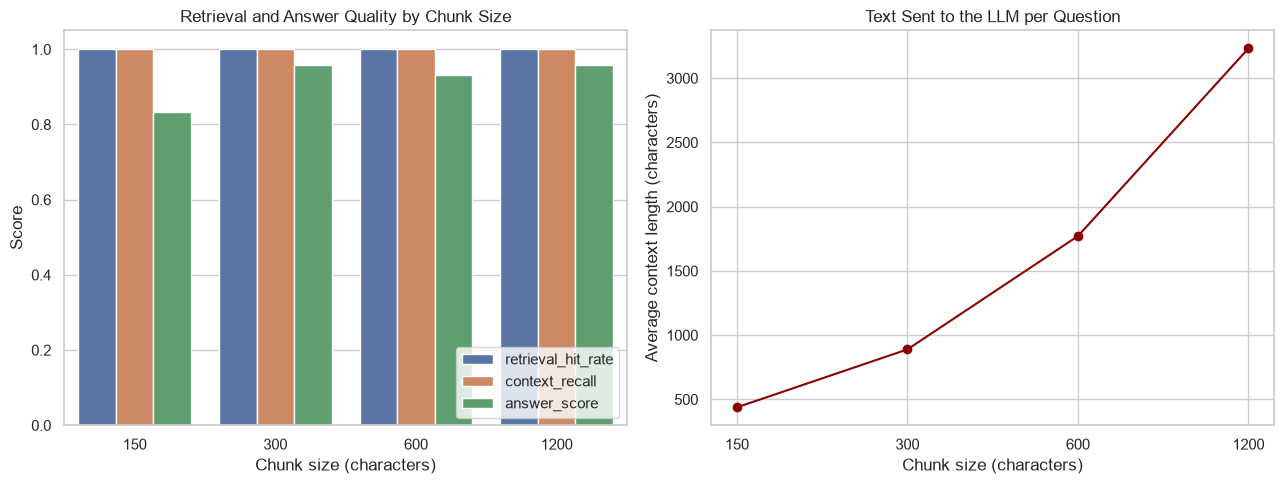

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_df = summary[["retrieval_hit_rate", "context_recall", "answer_score"]].reset_index().melt("chunk_size", var_name="metric", value_name="value")
sns.barplot(data=plot_df, x="chunk_size", y="value", hue="metric", ax=axes[0])
axes[0].set_title("Retrieval and Answer Quality by Chunk Size")
axes[0].set_xlabel("Chunk size (characters)")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.05)
axes[0].legend(loc="lower right")

axes[1].plot(summary.index.astype(str), summary["avg_context_chars"], marker="o", color="darkred")
axes[1].set_title("Text Sent to the LLM per Question")
axes[1].set_xlabel("Chunk size (characters)")
axes[1].set_ylabel("Average context length (characters)")

plt.tight_layout()
plt.savefig("results/chunk_size_comparison.png", dpi=120)
plt.show()

### Looking at where answers differ

Questions where at least one chunk size got a different score:

In [22]:
diff_q = grid[grid.nunique(axis=1) > 1].index.tolist()
for qid in diff_q:
    q = test_questions[int(qid[1:]) - 1]["question"]
    print(f"{qid}: {q}")
    for row in results[results["question"] == q].itertuples():
        print(f"   {row.chunk_size:>5} | recall {row.context_recall:.0%} | answer {row.answer_score:.0%} | {row.answer[:150]}")
    print()

Q3: How long is paternity leave and within what time must it be taken?
     150 | recall 100% | answer 50% | Paternity leave is 26 weeks long, and it must be taken within 3 months of the child's birth.
     300 | recall 100% | answer 100% | Paternity leave is 15 days, and it must be taken within 3 months of the child's birth.
     600 | recall 100% | answer 100% | Paternity leave is 15 days, and it must be taken within 3 months of the child's birth.
    1200 | recall 100% | answer 100% | Paternity leave is 15 days of paid leave. It must be taken within 3 months of the child's birth.

Q4: How many days a week do hybrid employees need to be in the office, and which are the anchor days?
     150 | recall 100% | answer 100% | Hybrid employees need to work from the office at least 3 days per week. The anchor days are Tuesday and Thursday.
     300 | recall 100% | answer 100% | Hybrid employees need to be in the office for at least 3 days per week. These are the anchor days, which include Tu

## 10. Findings

| Chunk size | Chunks | Retrieval hit | Context recall | Answer score | Fully correct | Avg context | Avg time |
|---|---|---|---|---|---|---|---|
| 150 | 142 | 100% | 100% | 83% | 9 / 12 | 438 chars | 12.5 s |
| **300** | 72 | 100% | 100% | **96%** | **11 / 12** | 889 chars | 16.2 s |
| 600 | 37 | 100% | 100% | 93% | 10 / 12 | 1,771 chars | 24.7 s |
| 1200 | 19 | 100% | 100% | 96% | 11 / 12 | 3,232 chars | 39.0 s |

**1. Retrieval worked at every chunk size.** For all 12 questions and all 4 chunk sizes, the top 3 chunks came from the correct document and contained all the key facts. The documents are short and each covers a clearly different topic, so finding the right part was easy. This means the differences in answer quality came from **how well the LLM could use the retrieved text**, not from retrieval failing.

**2. 150 characters was clearly the worst (9/12).** Very small chunks cut sentences away from their subject:
- Q3 (paternity leave): the answer said "26 weeks", which is the *maternity* leave number. A tiny chunk had the maternity sentence and the start of the paternity sentence together, and the model mixed them up.
- Q8 (stolen laptop): the "within 1 hour" fact was retrieved, but the model answered from another fragment about the police report (24 hours) and missed the actual answer.

With small chunks, the model gets disconnected pieces without the section heading or the full sentence, so it's easier to confuse similar facts.

**3. 300 and 1200 tied for the best answers (11/12), but 300 is much cheaper.** 1200-character chunks send about 3.6x more text to the LLM (3,232 vs 889 characters) and take 2.4x longer (39 s vs 16 s per question) for the same score. With `top_k = 3`, three 1200-character chunks are almost a whole document, so at that size it's barely "retrieval" any more.

**4. 600 lost one point by chance, not because of retrieval.** In Q4, the context had both anchor days but the model only mentioned Thursday. This is a small-model slip; one question out of 12 is not a real difference between 300, 600 and 1200.

**5. One question failed at every chunk size.** Q2 asks two things (carry forward *and* encashment). Every chunk size retrieved both facts, but the model answered only the first part each time. This is a limit of the 0.5B model with two-part questions, so changing the chunk size doesn't fix it.

**6. The model made up an answer for a question not in the documents.** For "What is the policy on pets in the office?" it should have said it doesn't know, but it answered with unrelated text about locking laptops. Small models don't always follow the "say I don't know" instruction. A bigger LLM or a minimum similarity score for retrieved chunks would help.

### Best chunk size: 300 characters

300 characters (about 2–3 sentences, with 15% overlap) gave the joint-best answer quality with a small context and fast answers. It's big enough to keep a full sentence together with its subject, which fixed the mix-ups seen at 150, and small enough that the LLM isn't given a lot of unrelated text.

**Limitations:** only 12 test questions, 5 short documents and one run, and the scoring checks for key facts with string matching. With longer documents, or questions that need information from several sections, a bigger chunk size (around 500–600) might do better, so the experiment should be repeated on the real documents before choosing a chunk size.
